# 皮膚病灶分割：FAT-Net、ResNet152V2、VGG16、EfficientNetB5

以ISIC 2018、ISIC 2016與PH2資料集訓練並比較4種分割模型，輸出病灶區域的像素級遮罩。最終選用FAT-Net部署到網站與App。

資料夾結構：

```
data/
├── images/   皮膚影像(.jpg)
└── masks/    對應的標註遮罩(<影像名稱>_segmentation.png)
```

In [ ]:
import cv2
import numpy as np

import torch 
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Subset
from tqdm import tqdm

import albumentations as A

import os
import matplotlib.pyplot as plt

In [ ]:
import torch
from torchvision import models as resnet_model
from torch import nn

## 參數設定

In [ ]:
IMG_PATH = "data/images"
MASK_PATH = "data/masks"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE= 32
SIZE = 224
LEARNING_RATE = 0.0002
NUM_EPOCHS = 100
NUM_WORKERS = 2
PIN_MEMORY = True

In [ ]:
import torch
print(torch.cuda.is_available())

## PH2資料前處理

PH2資料集的影像與遮罩是`.bmp`格式，且遮罩命名為`_lesion`，先轉成與ISIC相同的格式與命名後，再和ISIC資料放在一起訓練。

In [ ]:
import os
from PIL import Image

def convert_bmp_to_png(folder_path):
    # 确保提供的路径存在
    if not os.path.exists(folder_path):
        print("指定的資料夾不存在。")
        return
    
    # 遍历文件夹中的所有文件
    for filename in os.listdir(folder_path):
        # 只处理 .bmp 文件
        if filename.endswith('.bmp'):
            # 建立完整文件路径
            bmp_path = os.path.join(folder_path, filename)
            png_path = os.path.join(folder_path, filename.replace('.bmp', '.png'))
            
            # 打开 .bmp 文件并将其保存为 .png 文件
            with Image.open(bmp_path) as img:
                img.save(png_path, 'PNG')
            
            print(f"已将 {filename} 转换为 {filename.replace('.bmp', '.png')}")
    
    print("所有 .bmp 文件已成功转换为 .png 格式。")

# 使用範例
folder_path = "data/PH2/mask"
convert_bmp_to_png(folder_path)

In [ ]:
import os
from PIL import Image

def convert_bmp_to_jpg(folder_path):
    # 确保提供的路径存在
    if not os.path.exists(folder_path):
        print("指定的資料夾不存在。")
        return
    
    # 遍历文件夹中的所有文件
    for filename in os.listdir(folder_path):
        # 只处理 .bmp 文件
        if filename.endswith('.bmp'):
            # 创建完整文件路径
            bmp_path = os.path.join(folder_path, filename)
            jpg_path = os.path.join(folder_path, filename.replace('.bmp', '.jpg'))
            
            # 打开 .bmp 文件并将其保存为 .jpg 文件
            with Image.open(bmp_path) as img:
                rgb_img = img.convert('RGB')  # 确保图像为 RGB 模式
                rgb_img.save(jpg_path, 'JPEG')
            
            print(f"已将 {filename} 转换为 {filename.replace('.bmp', '.jpg')}")
    
    print("所有 .bmp 文件已成功转换为 .jpg 格式。")

# 使用範例
folder_path = "data/PH2/image"
convert_bmp_to_jpg(folder_path)

In [ ]:
import os

def rename_images(folder_path):
    # 确保提供的路径存在
    if not os.path.exists(folder_path):
        print("指定的資料夾不存在。")
        return
    
    # 遍历文件夹中的所有文件
    for filename in os.listdir(folder_path):
        # 检查文件名是否包含 "_lesion" 并且扩展名为 ".png"
        if "_lesion" in filename and filename.endswith('.png'):
            # 构造新的文件名
            new_filename = filename.replace('_lesion', '_segmentation')
            
            # 创建完整文件路径
            old_file_path = os.path.join(folder_path, filename)
            new_file_path = os.path.join(folder_path, new_filename)
            
            # 重命名文件
            os.rename(old_file_path, new_file_path)
            print(f"已将 {filename} 重命名为 {new_filename}")
    
    print("所有符合条件的文件已成功重命名。")

# 使用範例
folder_path = "data/PH2/mask"
rename_images(folder_path)

## 1. 模型架構

### FAT-Net

In [ ]:
import torch
from torchvision import models as resnet_model
from torch import nn


class FAMBlock(nn.Module):
    def __init__(self, channels):
        super(FAMBlock, self).__init__()

        self.conv3 = nn.Conv2d(in_channels=channels, out_channels=channels, kernel_size=3, padding=1)
        self.conv1 = nn.Conv2d(in_channels=channels, out_channels=channels, kernel_size=1)

        self.relu3 = nn.ReLU(inplace=True)
        self.relu1 = nn.ReLU(inplace=True)

    def forward(self, x):
        x3 = self.conv3(x)
        x3 = self.relu3(x3)
        x1 = self.conv1(x)
        x1 = self.relu1(x1)
        out = x3 + x1

        return out


class DecoderBottleneckLayer(nn.Module):
    def __init__(self, in_channels, n_filters, use_transpose=True):
        super(DecoderBottleneckLayer, self).__init__()

        self.conv1 = nn.Conv2d(in_channels, in_channels // 4, 1)
        self.norm1 = nn.BatchNorm2d(in_channels // 4)
        self.relu1 = nn.ReLU(inplace=True)

        if use_transpose:
            self.up = nn.Sequential(
                nn.ConvTranspose2d(
                    in_channels // 4, in_channels // 4, 3, stride=2, padding=1, output_padding=1
                ),
                nn.BatchNorm2d(in_channels // 4),
                nn.ReLU(inplace=True)
            )
        else:
            self.up = nn.Upsample(scale_factor=2, align_corners=True, mode="bilinear")

        self.conv3 = nn.Conv2d(in_channels // 4, n_filters, 1)
        self.norm3 = nn.BatchNorm2d(n_filters)
        self.relu3 = nn.ReLU(inplace=True)

    def forward(self, x):
        x = self.conv1(x)
        x = self.norm1(x)
        x = self.relu1(x)
        x = self.up(x)
        x = self.conv3(x)
        x = self.norm3(x)
        x = self.relu3(x)
        return x


class SEBlock(nn.Module):
    def __init__(self, channel, r=16):
        super(SEBlock, self).__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Sequential(
            nn.Linear(channel, channel // r, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(channel // r, channel, bias=False),
            nn.Sigmoid(),
        )

    def forward(self, x):
        b, c, _, _ = x.size()
        # Squeeze
        y = self.avg_pool(x).view(b, c)
        # Excitation
        y = self.fc(y).view(b, c, 1, 1)
        # Fusion
        y = torch.mul(x, y)
        return y


class FAT_Net(nn.Module):
    def __init__(self, n_channels=3, n_classes=1):
        super(FAT_Net, self).__init__()

        transformer = torch.hub.load('facebookresearch/deit:main', 'deit_tiny_distilled_patch16_224', pretrained=True)
        resnet = resnet_model.resnet34(pretrained=True)

        self.firstconv = resnet.conv1
        self.firstbn = resnet.bn1
        self.firstrelu = resnet.relu
        self.encoder1 = resnet.layer1
        self.encoder2 = resnet.layer2
        self.encoder3 = resnet.layer3
        self.encoder4 = resnet.layer4

        self.patch_embed = transformer.patch_embed
        self.transformers = nn.ModuleList(
            [transformer.blocks[i] for i in range(12)]
        )

        self.conv_seq_img = nn.Conv2d(in_channels=192, out_channels=512, kernel_size=1, padding=0)
        self.se = SEBlock(channel=1024)
        self.conv2d = nn.Conv2d(in_channels=1024, out_channels=512, kernel_size=1, padding=0)

        self.FAMBlock1 = FAMBlock(channels=64)
        self.FAMBlock2 = FAMBlock(channels=128)
        self.FAMBlock3 = FAMBlock(channels=256)
        self.FAM1 = nn.ModuleList([self.FAMBlock1 for i in range(6)])
        self.FAM2 = nn.ModuleList([self.FAMBlock2 for i in range(4)])
        self.FAM3 = nn.ModuleList([self.FAMBlock3 for i in range(2)])

        filters = [64, 128, 256, 512]
        self.decoder4 = DecoderBottleneckLayer(filters[3], filters[2])
        self.decoder3 = DecoderBottleneckLayer(filters[2], filters[1])
        self.decoder2 = DecoderBottleneckLayer(filters[1], filters[0])
        self.decoder1 = DecoderBottleneckLayer(filters[0], filters[0])

        self.final_conv1 = nn.ConvTranspose2d(filters[0], 32, 4, 2, 1)
        self.final_relu1 = nn.ReLU(inplace=True)
        self.final_conv2 = nn.Conv2d(32, 32, 3, padding=1)
        self.final_relu2 = nn.ReLU(inplace=True)
        self.final_conv3 = nn.Conv2d(32, n_classes, 3, padding=1)


    def forward(self, x):
        b, c, h, w = x.shape

        e0 = self.firstconv(x)
        e0 = self.firstbn(e0)
        e0 = self.firstrelu(e0)

        e1 = self.encoder1(e0)
        e2 = self.encoder2(e1)
        e3 = self.encoder3(e2)
        feature_cnn = self.encoder4(e3)

        emb = self.patch_embed(x)
        for i in range(12):
            emb = self.transformers[i](emb)
        feature_tf = emb.permute(0, 2, 1)
        feature_tf = feature_tf.view(b, 192, 14, 14)
        feature_tf = self.conv_seq_img(feature_tf)

        feature_cat = torch.cat((feature_cnn, feature_tf), dim=1)
        feature_att = self.se(feature_cat)
        feature_out = self.conv2d(feature_att)

        for i in range(2):
            e3 = self.FAM3[i](e3)
        for i in range(4):
            e2 = self.FAM2[i](e2)
        for i in range(6):
            e1 = self.FAM1[i](e1)
        d4 = self.decoder4(feature_out) + e3
        d3 = self.decoder3(d4) + e2
        d2 = self.decoder2(d3) + e1

        out1 = self.final_conv1(d2)
        out1 = self.final_relu1(out1)
        out = self.final_conv2(out1)
        out = self.final_relu2(out)
        out = self.final_conv3(out)

        return out

### 比較用模型

以下3個模型用於與FAT-Net比較，要訓練哪一個模型時，取消對應區塊的註解即可。

#### ResNet152V2

In [ ]:
    # import torch
    # import torch.nn as nn
    # import torchvision.models as models

    # class ResNet152V2Segmentation(nn.Module):
    #     def __init__(self, num_classes=1):
    #         super(ResNet152V2Segmentation, self).__init__()
            
    #         # 加载预训练的ResNet152模型
    #         resnet152 = models.resnet152(pretrained=True)
            
    #         # 去掉最后的全连接层
    #         self.encoder = nn.Sequential(*list(resnet152.children())[:-2])
            
    #         # 定义分割头
    #         self.segmentation_head = nn.Sequential(
    #             nn.Conv2d(2048, 512, kernel_size=3, padding=1),
    #             nn.ReLU(inplace=True),
    #             nn.Conv2d(512, num_classes, kernel_size=1)
    #         )
            
    #         # 初始化分割头的权重
    #         self._initialize_weights()

    #     def forward(self, x):
    #         # 将输入传入编码器
    #         x = self.encoder(x)
            
    #         # 将输出传入分割头
    #         x = self.segmentation_head(x)
            
    #         # 上采样输出到输入的大小
    #         x = nn.functional.interpolate(x, scale_factor=32, mode='bilinear', align_corners=True)
            
    #         return x
        
    #     def _initialize_weights(self):
    #         for m in self.segmentation_head.modules():
    #             if isinstance(m, nn.Conv2d):
    #                 nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
    #             elif isinstance(m, nn.BatchNorm2d):
    #                 nn.init.constant_(m.weight, 1)
    #                 nn.init.constant_(m.bias, 0)

    # # # 示例使用
    # # if __name__ == "__main__":
    # #     model = ResNet152V2Segmentation(num_classes=21)
    # #     input_tensor = torch.randn(1, 3, 224, 224)
    # #     output = model(input_tensor)
    # #     print(output.shape)  # 应该输出 torch.Size([1, 21, 224, 224])

#### EfficientNetB5(需安裝`efficientnet_pytorch`)

In [ ]:
# import torch
# import torch.nn as nn
# from efficientnet_pytorch import EfficientNet

# class EfficientNetB5_Segmentation(nn.Module):
#     def __init__(self, num_classes = 1):
#         super(EfficientNetB5_Segmentation, self).__init__()
#         self.encoder = EfficientNet.from_pretrained('efficientnet-b5')
        
#         self.decoder = nn.Sequential(
#             nn.ConvTranspose2d(2048, 512, kernel_size=4, stride=2, padding=1),
#             nn.BatchNorm2d(512),
#             nn.ReLU(inplace=True),
#             nn.ConvTranspose2d(512, 256, kernel_size=4, stride=2, padding=1),
#             nn.BatchNorm2d(256),
#             nn.ReLU(inplace=True),
#             nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1),
#             nn.BatchNorm2d(128),
#             nn.ReLU(inplace=True),
#             nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),
#             nn.BatchNorm2d(64),
#             nn.ReLU(inplace=True),
#             nn.ConvTranspose2d(64, num_classes, kernel_size=4, stride=2, padding=1)
#         )
        
#     def forward(self, x):
#         x = self.encoder.extract_features(x)
#         x = self.decoder(x)
#         return x

# # # 示例使用
# # num_classes = 1  # 例如，二分类分割任务
# # model = EfficientNetB5_Segmentation(num_classes)

# # # 打印模型架构
# # print(model)

#### VGG16

In [ ]:
# import torch
# import torch.nn as nn
# import torchvision.models as models
# import torch.nn.functional as F

# class VGG16Segmentation(nn.Module):
#     def __init__(self, num_classes = 1):
#         super(VGG16Segmentation, self).__init__()
#         vgg16 = models.vgg16(pretrained=True)
        
#         # Use the features part of VGG16
#         self.features = vgg16.features
        
#         # Replace the classifier part with a segmentation head
#         self.segmentation_head = nn.Sequential(
#             nn.Conv2d(512, 256, kernel_size=3, padding=1),
#             nn.ReLU(inplace=True),
#             nn.Conv2d(256, 128, kernel_size=3, padding=1),
#             nn.ReLU(inplace=True),
#             nn.Conv2d(128, num_classes, kernel_size=1)  # Final output channels should be equal to the number of classes
#         )
        
#         # Initialize the weights for the segmentation head
#         self._initialize_weights(self.segmentation_head)

#     def forward(self, x):
#         x = self.features(x)
#         x = self.segmentation_head(x)
#         x = F.interpolate(x, size=(224, 224), mode='bilinear', align_corners=False)  # Upsample to the input image size
#         return x
    
#     def _initialize_weights(self, module):
#         for m in module.modules():
#             if isinstance(m, nn.Conv2d):
#                 nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
#                 if m.bias is not None:
#                     nn.init.constant_(m.bias, 0)
#             elif isinstance(m, nn.BatchNorm2d):
#                 nn.init.constant_(m.weight, 1)
#                 nn.init.constant_(m.bias, 0)
#             elif isinstance(m, nn.Linear):
#                 nn.init.normal_(m.weight, 0, 0.01)
#                 nn.init.constant_(m.bias, 0)

# # # Example usage
# # num_classes = 1  # Number of segmentation classes
# # model = VGG16Segmentation(num_classes)

# # # Print model architecture
# # print(model)

## 2. 準備資料

### 2.1 自訂Dataset

In [ ]:
class ISICDataset(Dataset):
    def __init__(self, images_path, masks_path, size, transform=None):
        self.images_path = images_path
        self.masks_path = masks_path
        self.transform = transform
        self.ids = [image_file[:-4] for image_file in os.listdir(images_path) if image_file.endswith('.jpg')]
        self.size = size

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, idx):
        image_path = os.path.join(self.images_path, self.ids[idx] + '.jpg')
        mask_path = os.path.join(self.masks_path, self.ids[idx] + '_segmentation.png')
        
        # Load image and mask
        img = cv2.imread(os.path.join(self.images_path, self.ids[idx] + '.jpg'), cv2.IMREAD_COLOR)
        mask = cv2.imread(os.path.join(self.masks_path, self.ids[idx] + '_segmentation.png'), cv2.IMREAD_GRAYSCALE)
        
         # Convert to RGB, And convert mask to binary
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        ret, mask = cv2.threshold(mask, 127, 255, cv2.THRESH_BINARY)
        
        if self.transform is not None:
            augmentations = self.transform(image=img, mask=mask)
            img = augmentations['image']
            mask = augmentations['mask']
        
        # Convert numpy arrays to PyTorch tensors
        img = torch.from_numpy(img).permute(2, 0, 1).float() / 255.
        mask = torch.from_numpy(mask).unsqueeze(0).float()
        mask[mask == 255.0] = 1.0

        return img, mask

### 2.2 載入資料

- 影像統一調整為224×224
- 資料增強：隨機旋轉(35度內)、水平翻轉(機率50%)、垂直翻轉(機率10%)
- 80%作為訓練資料、20%作為測試資料

In [ ]:
transform = A.Compose([
    A.Resize(height=SIZE, width=SIZE),
    A.Rotate(limit=35, p=1.0),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.1),
])

# 創建數據集
dataset = ISICDataset(images_path=IMG_PATH, masks_path=MASK_PATH, size=SIZE, transform=transform)

# 劃分訓練集和測試集
train_size = int(0.8 * len(dataset))
train_dataset = Subset(dataset, range(train_size))
test_dataset = Subset(dataset, range(train_size, len(dataset)))

# 創建 DataLoader
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False)

In [ ]:
print(len(test_loader))

### 2.3 確認資料是否正確載入

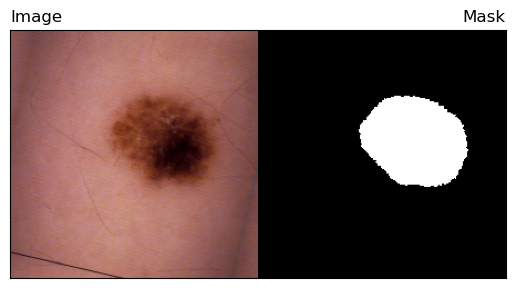

In [ ]:
img, mask = test_dataset[1]
img = img.permute(1, 2, 0).numpy()
mask = mask.permute(1, 2, 0).squeeze().numpy()
mask = cv2.resize(mask, (img.shape[1], img.shape[0]))
mask = np.expand_dims(mask, axis=2)
mask = np.repeat(mask, 3, axis=2)
concatenated_img = np.concatenate((img, mask), axis=1)

fig, ax = plt.subplots()
ax.imshow(concatenated_img)
ax.set_title('Image', loc='left')
ax.set_title('Mask', loc='right')

ax.set_xticks([])
ax.set_yticks([])
ax.set_xticklabels([])
ax.set_yticklabels([])

plt.show()

## 3. 訓練模型

損失函數使用`BCEWithLogitsLoss`，優化器使用Adam，並以混合精度訓練加速。

### FAT-Net

In [ ]:
# 初始化模型
model = FAT_Net().to(DEVICE)

# 定義損失函數
criterion = nn.BCEWithLogitsLoss()

# 定義優化器
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
# 定義混合精度訓練的 GradScaler
scaler = torch.cuda.amp.GradScaler()

### ResNet152V2

In [ ]:
# # 初始化模型
# model = ResNet152V2Segmentation().to(DEVICE)

# # 定義損失函數
# criterion = nn.BCEWithLogitsLoss()

# # 定義優化器
# optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
# # 定義混合精度訓練的 GradScaler
# scaler = torch.cuda.amp.GradScaler()

### EfficientNetB5

In [ ]:
# # 初始化模型
# model = EfficientNetB5_Segmentation().to(DEVICE)

# # 定義損失函數
# criterion = nn.BCEWithLogitsLoss()

# # 定義優化器
# optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
# # 定義混合精度訓練的 GradScaler
# scaler = torch.cuda.amp.GradScaler()

### VGG16

In [ ]:
# # 初始化模型
# model = VGG16Segmentation().to(DEVICE)

# # 定義損失函數
# criterion = nn.BCEWithLogitsLoss()

# # 定義優化器
# optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
# # 定義混合精度訓練的 GradScaler
# scaler = torch.cuda.amp.GradScaler()

### 評估指標：Dice Score與IoU

In [ ]:
def check_accuracy(loader, model, device="cuda"):
    num_correct = 0
    dice_score = 0
    model.eval()
    
    with torch.no_grad():
        for x, y in loader:
            x = x.to(device)
            y = y.to(device)
            preds = torch.sigmoid(model(x))
            preds = (preds > 0.5).float()
            num_correct += (preds == y).sum()
            dice_score += (2 * (preds * y).sum()) / (preds + y).sum() + 1e-8
            
    print(f"Dice score: {dice_score/len(loader)}")
    model.train()

In [ ]:
def check_iou(loader, model, device="cuda"):
    num_correct = 0
    iou_score = 0
    model.eval()
    
    with torch.no_grad():
        for x, y in loader:
            x = x.to(device)
            y = y.to(device)
            preds = torch.sigmoid(model(x))
            preds = (preds > 0.5).float()
            
            # 计算交并比 (IoU)
            intersection = (preds * y).sum()
            union = (preds + y).sum() - intersection
            iou_score += intersection / (union + 1e-8)
            
    print(f"IoU score: {iou_score / len(loader)}")
    model.train()

### 訓練迴圈

每個epoch都儲存一次checkpoint，訓練完成後再逐一評估，挑選表現最好的模型。

In [ ]:
batch_size = 16  # 例如，选择批量大小为 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)



for epoch in range(100): 
    
    loop = tqdm(enumerate(train_loader), total=len(train_loader), leave=False)
    
    if epoch != 0: #if epoch % 5 == 0 and epoch != 0:
        checkpoint = {'state_dict': model.state_dict(), 'optimizer': optimizer.state_dict(),
                      'epoch': epoch}
        torch.save(checkpoint, "machine_checkpointN1031_"+str(epoch)+"_.pth.tar")  
    
    
    for batch_idx, (images, masks) in loop:
        images, masks = images.to(DEVICE), masks.to(DEVICE)

        # Gradients to 0
        optimizer.zero_grad()

        # Forward 
        with torch.cuda.amp.autocast():
            outputs = model(images)
            loss = criterion(outputs, masks)
        
        # Backward
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        
        loop.set_description(f"Epoch[{epoch}/{NUM_EPOCHS}]")
        loop.set_postfix(loss = loss.item())


checkpoint = {'state_dict': model.state_dict(), 'optimizer': optimizer.state_dict()}
torch.save(checkpoint, "machine_checkpoint1020_last.pth.tar")

## 4. 評估模型

載入最終選用的FAT-Net模型：

In [ ]:
model.load_state_dict(torch.load("fatnet_segmentation.pth.tar")['state_dict'])

In [ ]:
check_iou(test_loader, model, DEVICE)

IoU score: 0.8795401453971863


逐一評估每個epoch的checkpoint：

In [ ]:
for i in range ( 1, 100 ):
    model.load_state_dict(torch.load("machine_checkpointN1031_"+str(i)+"_.pth.tar")['state_dict'])
    print ( i )
    check_accuracy(test_loader, model, DEVICE)
    

### 顯示原圖、標註遮罩與模型產生的遮罩

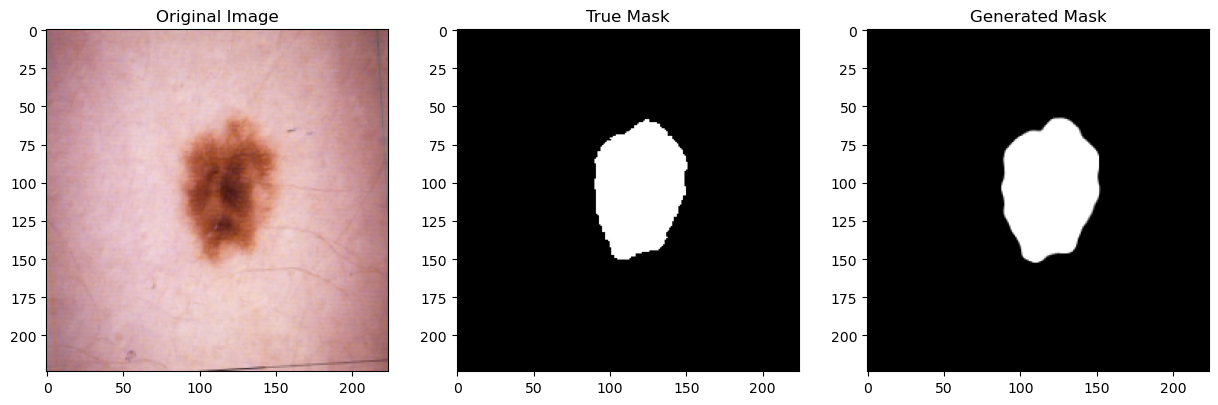

In [ ]:
# Load an example image and mask
img, true_mask = test_dataset[88]
img = img.permute(1, 2, 0).numpy()
true_mask = true_mask.permute(1, 2, 0).squeeze().numpy()

# Generate a predicted mask using your trained U-net model
with torch.no_grad():
    img_tensor = torch.Tensor(img).unsqueeze(0).permute(0, 3, 1, 2).to(DEVICE)
    generated_mask = model(img_tensor).squeeze().cpu().numpy()

# Resize and stack the masks for display
true_mask_resized = cv2.resize(true_mask, (img.shape[1], img.shape[0]))
true_mask_stacked = np.stack((true_mask_resized,)*3, axis=-1)

generated_mask_resized = cv2.resize(generated_mask, (img.shape[1], img.shape[0]))
generated_mask_stacked = np.stack((generated_mask_resized,)*3, axis=-1)

# Combine the image and masks into a single plot
fig, ax = plt.subplots(1, 3, figsize=(15, 5))

ax[0].imshow(img)
ax[0].set_title('Original Image')

ax[1].imshow(true_mask_stacked)
ax[1].set_title('True Mask')

ax[2].imshow(generated_mask_stacked)
ax[2].set_title('Generated Mask')
plt.savefig('image_masks2.png')
plt.show()

## 5. 匯出成PyTorch Mobile模型(.ptl)

供Android App使用。

In [ ]:
import torch
import timm
import torch.utils.data.distributed
from torch.utils.mobile_optimizer import optimize_for_mobile

# 定义模型参数
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
#device = torch.device('cpu')

# 创建模型并加载权重
model = FAT_Net().to(device)  # 使用自定义模型类
model.load_state_dict(torch.load("fatnet_segmentation.pth.tar")['state_dict'])
model.eval()

# 将输入张量移动到与模型相同的设备
input_tensor = torch.rand(1, 3, 224, 224).to(device)

# 保存模型为.pt文件
mobile = torch.jit.trace(model, input_tensor)
mobile_optimized = optimize_for_mobile(mobile)
mobile_optimized._save_for_lite_interpreter("maskmodel2.ptl")